# Paso 3 · Partición honesta y modelo base

**Objetivo:** medir de verdad qué puede predecir el modelo con datos de Reef Check, empezando por lo más simple.

Tres ideas clave:
1. **Partición temporal:** entrenamos con 2003–2014 y probamos con 2015–2019. Así el test incluye el **evento global de 2016**, que nunca vio el modelo. Es como usarlo "en el futuro".
2. **Primero lo simple:** si un modelo solo con `tsa_dhw` funciona casi igual que uno con 15 variables, nos quedamos con el simple.
3. **Restricción monótona:** obligamos al modelo a que *más calor nunca signifique menos blanqueamiento*.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

df = pd.read_csv("../data/coral_reefcheck.csv")
train = df[df["year"] <= 2014].copy()
test = df[df["year"] >= 2015].copy()
print(f"train {len(train)} · test {len(test)}")
print("Muestreos de test en sitios que el modelo nunca vio:", (~test["site_id"].isin(train["site_id"])).sum())

train 7915 · test 3264
Muestreos de test en sitios que el modelo nunca vio: 1470


## 1. ¿Qué queremos predecir?
En Reef Check el 66 % de los muestreos tiene 0 % de blanqueamiento y la mediana es 0. Por eso conviene predecir una **probabilidad** en lugar de un porcentaje exacto. Pero ¿probabilidad *de qué*?

- `> 0 %`: "se vio algún coral blanqueado".
- `> 10 %`: "blanqueamiento apreciable", más de 1 de cada 10 corales.

Probamos varios umbrales y comparamos un modelo **solo con calor** contra uno **con calor + contexto del sitio**.

**Métrica:** AUC. 0,5 = adivinar al azar, 1 = perfecto. Mide si el modelo ordena bien los muestreos: los que se blanquearon, ¿tienen más probabilidad que los que no?

In [2]:
HEAT = ["tsa_dhw", "tsa", "tsa_frequency", "sst"]
CONTEXT = HEAT + ["ssta_sd", "sst_sd", "depth_m", "abs_latitude", "turbidity", "cyclone_frequency",
                  "windspeed", "hard_coral_cover", "algae_cover", "distance_to_shore"]
MONOTONE_UP = ["tsa_dhw", "tsa", "tsa_frequency"]

def fit_xgb(X, y):
    mono = tuple(1 if c in MONOTONE_UP else 0 for c in X.columns)
    model = xgb.XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.03, subsample=0.8,
                              colsample_bytree=0.8, monotone_constraints=mono, eval_metric="logloss")
    return model.fit(X, y)

rows = []
for th in [0, 1, 5, 10, 20]:
    y_tr, y_te = (train["percent_bleaching"] > th).astype(int), (test["percent_bleaching"] > th).astype(int)
    logit = LogisticRegression().fit(np.log1p(train[["tsa_dhw"]]), y_tr)
    rows.append({
        "umbral": f"> {th} %",
        "prevalencia": round(y_te.mean(), 3),
        "solo tsa_dhw (logística)": roc_auc_score(y_te, logit.predict_proba(np.log1p(test[["tsa_dhw"]]))[:, 1]),
        "calor (xgb)": roc_auc_score(y_te, fit_xgb(train[HEAT], y_tr).predict_proba(test[HEAT])[:, 1]),
        "calor + contexto (xgb)": roc_auc_score(y_te, fit_xgb(train[CONTEXT], y_tr).predict_proba(test[CONTEXT])[:, 1]),
    })
pd.DataFrame(rows).round(3)

,umbral,prevalencia,solo tsa_dhw (logística),calor (xgb),calor + contexto (xgb)
0,> 0 %,0.345,0.554,0.553,0.711
1,> 1 %,0.244,0.570,0.560,0.701
2,> 5 %,0.117,0.614,0.602,0.667
3,> 10 %,0.071,0.648,0.621,0.657
4,> 20 %,0.039,0.707,0.638,0.632


### Cómo leer la tabla
- **Con umbral bajo (> 0 %),** el calor apenas predice (AUC ≈ 0,55) y el contexto sube mucho (≈ 0,71). Ese blanqueamiento leve parece depender sobre todo del **lugar**: siempre hay algún coral pálido en ciertos sitios, o ciertos equipos lo anotan más.
- **Con umbral alto,** la ventaja del contexto casi desaparece (> 10 %) y en > 20 % el calor solo **gana**. El blanqueamiento importante sí lo explica el calor; el contexto empieza a sobreajustar a los sitios del entrenamiento.

👉 Para la app, *"probabilidad de blanqueamiento apreciable (> 10 %)"* encaja con la pregunta que queremos responder: **¿qué hace el calor?**

## 2. Modelo base: probabilidad de blanqueamiento > 10 %
Comparamos `tsa_dhw` (estándar de NOAA) con `ssta_dhw` (la que usaba el modelo anterior).

In [3]:
TH = 10
y_tr = (train["percent_bleaching"] > TH).astype(int)
y_te = (test["percent_bleaching"] > TH).astype(int)

def report(name, p):
    return {"modelo": name, "AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
            "Brier": brier_score_loss(y_te, p)}

results = [report("prevalencia (adivinar la media)", np.full(len(test), y_tr.mean()))]
for f in ["ssta_dhw", "tsa_dhw"]:
    m = LogisticRegression().fit(np.log1p(train[[f]]), y_tr)
    results.append(report(f"logística · {f}", m.predict_proba(np.log1p(test[[f]]))[:, 1]))
heat_model = fit_xgb(train[HEAT], y_tr)
results.append(report("xgb monótono · calor", heat_model.predict_proba(test[HEAT])[:, 1]))
pd.DataFrame(results).round(3)

,modelo,AUC,PR-AUC,Brier
0,prevalencia (adivinar la media),0.500,0.071,0.067
1,logística · ssta_dhw,0.651,0.136,0.065
2,logística · tsa_dhw,0.648,0.141,0.065
3,xgb monótono · calor,0.621,0.112,0.067


**`tsa_dhw` vs `ssta_dhw`:** dentro de Reef Check rinden parecido (la diferencia grande que vimos antes venía de mezclar fuentes). Elegimos `tsa_dhw` porque es la definición de NOAA: sus umbrales (4 y 8) son interpretables y es el dato que NOAA publica a diario, la base para una futura capa "Hoy".

**PR-AUC** es útil cuando el evento es raro (aquí ~6 %): compárala con la prevalencia. **Brier** mide el error de las probabilidades (más bajo es mejor).

## 3. La curva de riesgo
Lo que verá el usuario en la app: cómo sube la probabilidad de blanqueamiento apreciable al acumular calor. La sombra marca la zona con pocos datos (DHW > 12).

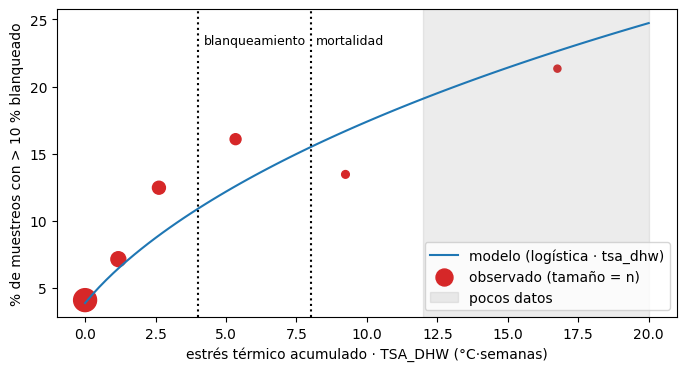

In [4]:
dhw = np.linspace(0, 20, 81)
logit = LogisticRegression().fit(np.log1p(train[["tsa_dhw"]]), y_tr)
risk = logit.predict_proba(np.log1p(pd.DataFrame({"tsa_dhw": dhw})))[:, 1]

obs = df.assign(bin=pd.cut(df["tsa_dhw"], [-0.1, 0, 2, 4, 8, 12, 40]))
obs = obs.groupby("bin", observed=True).agg(x=("tsa_dhw", "median"), y=("percent_bleaching", lambda s: (s > TH).mean()), n=("tsa_dhw", "size"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dhw, risk * 100, label="modelo (logística · tsa_dhw)")
ax.scatter(obs["x"], obs["y"] * 100, s=np.sqrt(obs["n"]) * 3, color="tab:red", label="observado (tamaño = n)")
ax.axvspan(12, 20, color="grey", alpha=0.15, label="pocos datos")
for v, t in [(4, "blanqueamiento"), (8, "mortalidad")]:
    ax.axvline(v, ls=":", color="k"); ax.text(v + 0.2, ax.get_ylim()[1] * 0.9, t, fontsize=9)
ax.set(xlabel="estrés térmico acumulado · TSA_DHW (°C·semanas)", ylabel="% de muestreos con > 10 % blanqueado")
ax.legend(); plt.show()

## 4. ¿Las probabilidades son fiables? (calibración)
Si el modelo dice "20 %", ¿en esos casos se blanqueó de verdad ~1 de cada 5? Los puntos deberían quedar cerca de la diagonal.

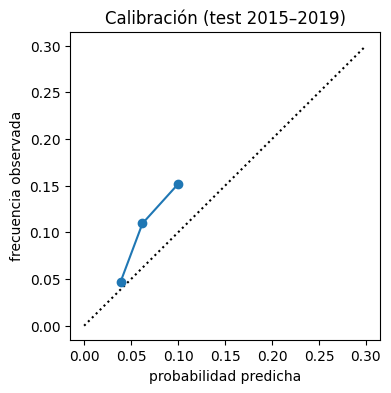

In [5]:
p = logit.predict_proba(np.log1p(test[["tsa_dhw"]]))[:, 1]
frac, mean_p = calibration_curve(y_te, p, n_bins=6, strategy="quantile")
plt.figure(figsize=(4, 4))
plt.plot([0, 0.3], [0, 0.3], "k:"); plt.plot(mean_p, frac, "o-")
plt.xlabel("probabilidad predicha"); plt.ylabel("frecuencia observada"); plt.title("Calibración (test 2015–2019)")
plt.show()

**Lectura:** los puntos quedan **por encima** de la diagonal, así que el modelo se queda corto en 2015–2019. En esos años (con el evento global de 2016) hubo más blanqueamiento apreciable que en 2003–2014 para el mismo calor. Puede ser una tendencia real (arrecifes más estresados con los años) o cambios en el muestreo. Lo tendremos en cuenta en el paso 4 (por ejemplo, probando `year` como variable).

## 5. Conclusiones y decisión

Lo esperable con estos datos:
- La señal del calor es **real pero modesta** (AUC ~0,65). Un muestreo en un día y un lugar concretos tiene mucho ruido: el momento del muestreo, las especies, la experiencia del equipo…
- El modelo **simple** (solo `tsa_dhw`) compite con los complejos para el blanqueamiento importante. Es más honesto, más fácil de explicar y no sobreajusta.
- Para la app, el número principal pasaría a ser un **riesgo**: *"con este calor, en ~X de cada 100 muestreos se ve un blanqueamiento apreciable"*.

✍️ **Tus decisiones para el paso 4:**
1. ¿Umbral de 10 % como definición de "blanqueamiento apreciable"?
2. ¿Probamos a añadir **solo** variables con sentido biológico (variabilidad térmica `ssta_sd`, latitud, profundidad) al modelo de calor, una por una, y nos quedamos con las que mejoren en test?

_(tus notas aquí)_